In [49]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [50]:
# Load California Housing Dataset

housing = fetch_california_housing()

X = housing.data
y = housing.target

print("Feature Shape :", X.shape)
print("Target Shape :", y.shape)

Feature Shape : (20640, 8)
Target Shape : (20640,)


In [51]:
# Convert to DataFrame

df = pd.DataFrame(X, columns=housing.feature_names)

df["Price"] = y

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [52]:
print(df.isnull().sum())

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
Price         0
dtype: int64


In [53]:
X = df.drop("Price", axis=1)

y = df["Price"]

In [54]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(16512, 8)
(4128, 8)


In [55]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [56]:
linear = LinearRegression()

linear.fit(X_train_scaled, y_train)

linear_pred = linear.predict(X_test_scaled)

mse = mean_squared_error(y_test, linear_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, linear_pred)

print("Linear Regression")

print("MSE :", mse)

print("RMSE :", rmse)

print("R2 Score :", r2)

Linear Regression
MSE : 0.5558915986952442
RMSE : 0.7455813830127763
R2 Score : 0.575787706032451


In [57]:
poly2 = PolynomialFeatures(degree=2)

X_train_poly2 = poly2.fit_transform(X_train_scaled)

X_test_poly2 = poly2.transform(X_test_scaled)

model2 = LinearRegression()

model2.fit(X_train_poly2, y_train)

pred2 = model2.predict(X_test_poly2)

mse2 = mean_squared_error(y_test, pred2)

rmse2 = np.sqrt(mse2)

r22 = r2_score(y_test, pred2)

print("Degree 2")

print("MSE :", mse2)

print("RMSE :", rmse2)

print("R2 :", r22)

Degree 2
MSE : 0.46430152383012785
RMSE : 0.6813967448044699
R2 : 0.6456819729261861


In [58]:
poly3 = PolynomialFeatures(degree=3)

X_train_poly3 = poly3.fit_transform(X_train_scaled)

X_test_poly3 = poly3.transform(X_test_scaled)

model3 = LinearRegression()

model3.fit(X_train_poly3, y_train)

pred3 = model3.predict(X_test_poly3)

mse3 = mean_squared_error(y_test, pred3)

rmse3 = np.sqrt(mse3)

r23 = r2_score(y_test, pred3)

print("Degree 3")

print("MSE :", mse3)

print("RMSE :", rmse3)

print("R2 :", r23)

Degree 3
MSE : 25.40713711635129
RMSE : 5.040549287166161
R2 : -18.38870805850092


In [59]:
poly4 = PolynomialFeatures(degree=4)

X_train_poly4 = poly4.fit_transform(X_train_scaled)

X_test_poly4 = poly4.transform(X_test_scaled)

model4 = LinearRegression()

model4.fit(X_train_poly4, y_train)

pred4 = model4.predict(X_test_poly4)

mse4 = mean_squared_error(y_test, pred4)

rmse4 = np.sqrt(mse4)

r24 = r2_score(y_test, pred4)

print("Degree 4")

print("MSE :", mse4)

print("RMSE :", rmse4)

print("R2 :", r24)

Degree 4
MSE : 15039.700366326168
RMSE : 122.63645610635594
R2 : -11476.104183546991


In [60]:
ridge = Ridge(alpha=1.0)

ridge.fit(X_train_scaled, y_train)

ridge_pred = ridge.predict(X_test_scaled)

ridge_mse = mean_squared_error(y_test, ridge_pred)

ridge_rmse = np.sqrt(ridge_mse)

ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge Regression")

print("MSE :", ridge_mse)

print("RMSE :", ridge_rmse)

print("R2 :", ridge_r2)

Ridge Regression
MSE : 0.5558548589435971
RMSE : 0.7455567442814779
R2 : 0.5758157428913684


In [61]:
lasso = Lasso(alpha=0.01)

lasso.fit(X_train_scaled, y_train)

lasso_pred = lasso.predict(X_test_scaled)

lasso_mse = mean_squared_error(y_test, lasso_pred)

lasso_rmse = np.sqrt(lasso_mse)

lasso_r2 = r2_score(y_test, lasso_pred)

print("Lasso Regression")

print("MSE :", lasso_mse)

print("RMSE :", lasso_rmse)

print("R2 :", lasso_r2)

Lasso Regression
MSE : 0.5482548967938964
RMSE : 0.7404423656125414
R2 : 0.5816154300698727


In [62]:
results = pd.DataFrame({
    "Model": [
        "Linear",
        "Polynomial Degree 2",
        "Polynomial Degree 3",
        "Polynomial Degree 4",
        "Ridge",
        "Lasso"
    ],
    "MSE": [
        mse,
        mse2,
        mse3,
        mse4,
        ridge_mse,
        lasso_mse
    ],
    "RMSE": [
        rmse,
        rmse2,
        rmse3,
        rmse4,
        ridge_rmse,
        lasso_rmse
    ],
    "R2 Score": [
        r2,
        r22,
        r23,
        r24,
        ridge_r2,
        lasso_r2
    ]
})

results

,Model,MSE,RMSE,R2 Score
0,Linear,0.555892,0.745581,0.575788
1,Polynomial Degree 2,0.464302,0.681397,0.645682
2,Polynomial Degree 3,25.407137,5.040549,-18.388708
3,Polynomial Degree 4,15039.700366,122.636456,-11476.104184
4,Ridge,0.555855,0.745557,0.575816
5,Lasso,0.548255,0.740442,0.581615


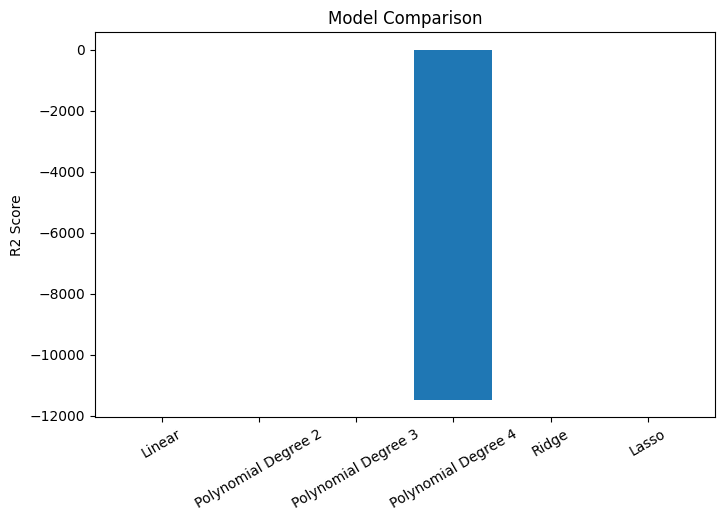

In [63]:
plt.figure(figsize=(8,5))

plt.bar(results["Model"], results["R2 Score"])

plt.xticks(rotation=30)

plt.title("Model Comparison")

plt.ylabel("R2 Score")

plt.show()

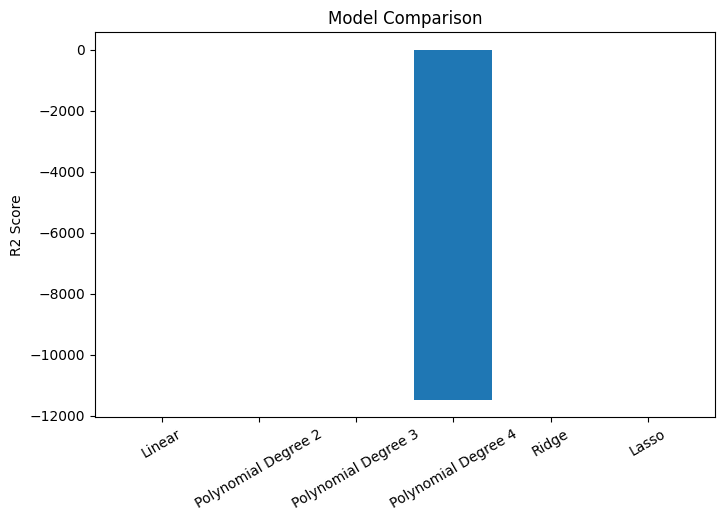

In [64]:
plt.figure(figsize=(8,5))

plt.bar(results["Model"], results["R2 Score"])

plt.xticks(rotation=30)

plt.title("Model Comparison")

plt.ylabel("R2 Score")

plt.savefig("Model_Comparison.png")   # Save graph

plt.show()